# 🌍 Life Expectancy Prediction using Machine Learning

This project predicts **life expectancy** using socioeconomic and health-related indicators from the **WHO Life Expectancy dataset**. The workflow includes data preprocessing, exploratory data analysis (EDA), feature engineering, and machine learning model comparison to identify the most effective predictive model.

### 📌 Project Workflow

- Data Cleaning
- Exploratory Data Analysis (EDA)
- Feature Engineering
- Data Preprocessing
- Machine Learning Model Training
- Model Evaluation
- Feature Importance Analysis

### 🤖 Machine Learning Models Used

- Linear Regression
- Random Forest Regressor
- XGBoost Regressor

> **Goal:** Build an end-to-end regression pipeline to predict life expectancy and identify the key factors influencing population health.

## Import Libraries

In [7]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from xgboost import XGBRegressor

# Global settings
RANDOM_STATE = 42
TARGET = "Life expectancy"
STATUS_PALETTE = {"Developed": "#2a9d8f", "Developing": "#e76f51"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", None)

##  Load Dataset

In [43]:
DATA_PATH = r"C:\Users\DELL\Desktop\Life-Expectancy-Prediction\data\Life_Expectancy_Data.csv"

life_df = pd.read_csv(DATA_PATH)
print(f"Rows: {life_df.shape[0]:,} | Columns: {life_df.shape[1]}")
life_df.head()

Rows: 2,938 | Columns: 22


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


##  Dataset Overview

###  Structure and data types

In [9]:
life_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

###  Summary statistics

In [10]:
life_df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Year,2938.0,2007.52,4.61,2000.00,2004.00,2008.00,2012.00,2.015000e+03
Life expectancy,2928.0,69.22,9.52,36.30,63.10,72.10,75.70,8.900000e+01
Adult Mortality,2928.0,164.80,124.29,1.00,74.00,144.00,228.00,7.230000e+02
infant deaths,2938.0,30.30,117.93,0.00,0.00,3.00,22.00,1.800000e+03
Alcohol,2744.0,4.60,4.05,0.01,0.88,3.76,7.70,1.787000e+01
percentage expenditure,2938.0,738.25,1987.91,0.00,4.69,64.91,441.53,1.947991e+04
Hepatitis B,2385.0,80.94,25.07,1.00,77.00,92.00,97.00,9.900000e+01
Measles,2938.0,2419.59,11467.27,0.00,0.00,17.00,360.25,2.121830e+05
BMI,2904.0,38.32,20.04,1.00,19.30,43.50,56.20,8.730000e+01
under-five deaths,2938.0,42.04,160.45,0.00,0.00,4.00,28.00,2.500000e+03


###  Coverage: countries, years and country status

In [11]:
rows_per_country = life_df["Country"].value_counts()

print(f"Countries: {life_df['Country'].nunique()} | Years: {life_df['Year'].min()}-{life_df['Year'].max()}")
display(rows_per_country.value_counts().rename_axis("Rows per country").to_frame("Number of countries"))
display(life_df["Status"].value_counts().rename_axis("Status").to_frame("Rows"))

Countries: 193 | Years: 2000-2015


,Number of countries
Rows per country,
16,183
1,10


,Rows
Status,
Developing,2426
Developed,512


###  Raw column names

Several raw column names contain leading, trailing or repeated spaces (for example `' BMI '` and `' thinness  1-19 years'`). These are cleaned further

In [12]:
print(life_df.columns.tolist())

['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years', ' thinness 5-9 years', 'Income composition of resources', 'Schooling']


###  Feature descriptions

The definitions below follow the public documentation of this dataset.

| Feature | Description |
|---|---|
| `Country`, `Year`, `Status` | Country name, year (2000–2015) and *Developed* / *Developing* classification |
| `Life expectancy` | **Target.** Life expectancy at birth, in years |
| `Adult Mortality` | Probability of dying between 15 and 60 years of age, per 1,000 population |
| `infant deaths`, `under-five deaths` | Infant and under-five deaths, per 1,000 population |
| `Alcohol` | Recorded alcohol consumption per capita (15+), litres of pure alcohol |
| `percentage expenditure` | Health expenditure as a percentage of GDP per capita |
| `Total expenditure` | Government health expenditure as a percentage of total government expenditure |
| `Hepatitis B`, `Polio`, `Diphtheria` | Immunisation coverage among 1-year-olds (%) |
| `Measles` | Reported measles cases |
| `BMI` | Average body mass index of the population |
| `HIV/AIDS` | Deaths per 1,000 live births due to HIV/AIDS (ages 0–4) |
| `GDP`, `Population` | GDP per capita (USD) and population |
| `thinness 1-19 years`, `thinness 5-9 years` | Prevalence of thinness among older children and adolescents, and among children aged 5–9 (%) |
| `Income composition of resources` | Human Development Index in terms of income composition of resources (0–1) |
| `Schooling` | Average number of years of schooling |

##  Data Cleaning


### Standardise column names

In [13]:
clean_df = life_df.copy()
clean_df.columns = clean_df.columns.str.replace(r"\s+", " ", regex=True).str.strip()

renamed = {old: new for old, new in zip(life_df.columns, clean_df.columns) if old != new}
pd.DataFrame({"Original name": [repr(k) for k in renamed], "Cleaned name": [repr(v) for v in renamed.values()]})

,Original name,Cleaned name
0,'Life expectancy ','Life expectancy'
1,'Measles ','Measles'
2,' BMI ','BMI'
3,'under-five deaths ','under-five deaths'
4,'Diphtheria ','Diphtheria'
5,' HIV/AIDS','HIV/AIDS'
6,' thinness 1-19 years','thinness 1-19 years'
7,' thinness 5-9 years','thinness 5-9 years'


### Duplicate rows
Checks for fully duplicated rows and for repeated `(Country, Year)` records.

In [14]:
print(f"Fully duplicated rows:       {clean_df.duplicated().sum()}")
print(f"Duplicate (Country, Year):   {clean_df.duplicated(subset=['Country', 'Year']).sum()}")

Fully duplicated rows:       0
Duplicate (Country, Year):   0


### Data types
`Country` and `Status` are text and are encoded in Section 8. All other columns are numeric and already have appropriate types; `Year` is kept as a numeric feature.

In [15]:
display(clean_df.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("Number of columns"))
print("Non-numeric columns:", clean_df.select_dtypes(exclude="number").columns.tolist())

,Number of columns
dtype,
float64,16
int64,4
object,2


Non-numeric columns: ['Country', 'Status']


### Missing values
Missing values are concentrated in a handful of columns, most notably `Population`, `Hepatitis B` and `GDP`.

,Missing values,Missing (%)
Population,652,22.19
Hepatitis B,553,18.82
GDP,448,15.25
Total expenditure,226,7.69
Alcohol,194,6.60
Income composition of resources,167,5.68
Schooling,163,5.55
BMI,34,1.16
thinness 1-19 years,34,1.16
thinness 5-9 years,34,1.16


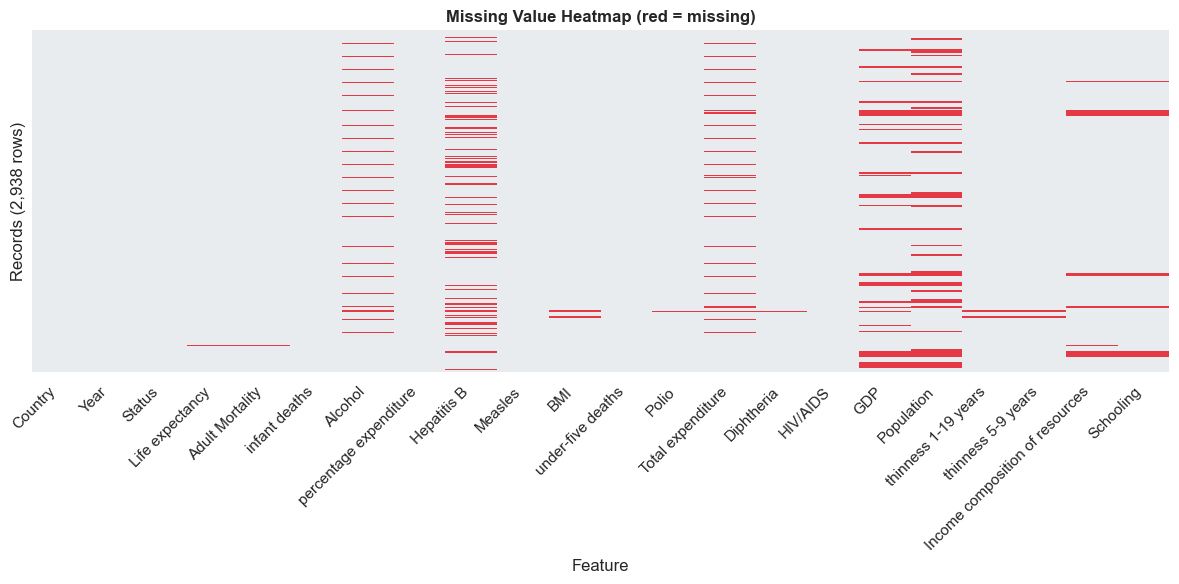

In [16]:
missing_summary = (
    clean_df.isnull().sum().to_frame("Missing values")
    .assign(**{"Missing (%)": lambda t: (t["Missing values"] / len(clean_df) * 100).round(2)})
    .query("`Missing values` > 0")
    .sort_values("Missing values", ascending=False)
)
display(missing_summary)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(clean_df.isnull(), cbar=False, yticklabels=False,
            cmap=sns.color_palette(["#e9ecef", "#e63946"]), ax=ax)
ax.set_title("Missing Value Heatmap (red = missing)")
ax.set_xlabel("Feature")
ax.set_ylabel(f"Records ({len(clean_df):,} rows)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

###  Rows with a missing target


In [17]:
missing_target = clean_df[clean_df[TARGET].isnull()]
print(f"Rows with missing '{TARGET}': {len(missing_target)}")
print(f"Of these, rows also missing 'Adult Mortality': {missing_target['Adult Mortality'].isnull().sum()}")
print("Countries affected:", ", ".join(sorted(missing_target["Country"])))

clean_df = clean_df.dropna(subset=[TARGET]).reset_index(drop=True)
print(f"\nShape after dropping them: {clean_df.shape}")

Rows with missing 'Life expectancy': 10
Of these, rows also missing 'Adult Mortality': 10
Countries affected: Cook Islands, Dominica, Marshall Islands, Monaco, Nauru, Niue, Palau, Saint Kitts and Nevis, San Marino, Tuvalu

Shape after dropping them: (2928, 22)


###  Outlier detection
Outliers are identified with the 1.5 × IQR rule on the 18 numeric indicators (the same columns the original notebook treated). The target and `Year` are not treated. Many of these "outliers" are genuine (for example very large populations or very high child-mortality countries), so they are **detected and visualised here but only treated in Section 9**, using fences learned from the training data alone.

,Outliers,Outliers (%)
Measles,542,18.5
HIV/AIDS,542,18.5
under-five deaths,394,13.5
percentage expenditure,388,13.3
GDP,363,14.6
infant deaths,315,10.8
Diphtheria,297,10.2
Population,294,12.9
Polio,278,9.6
Hepatitis B,252,10.6


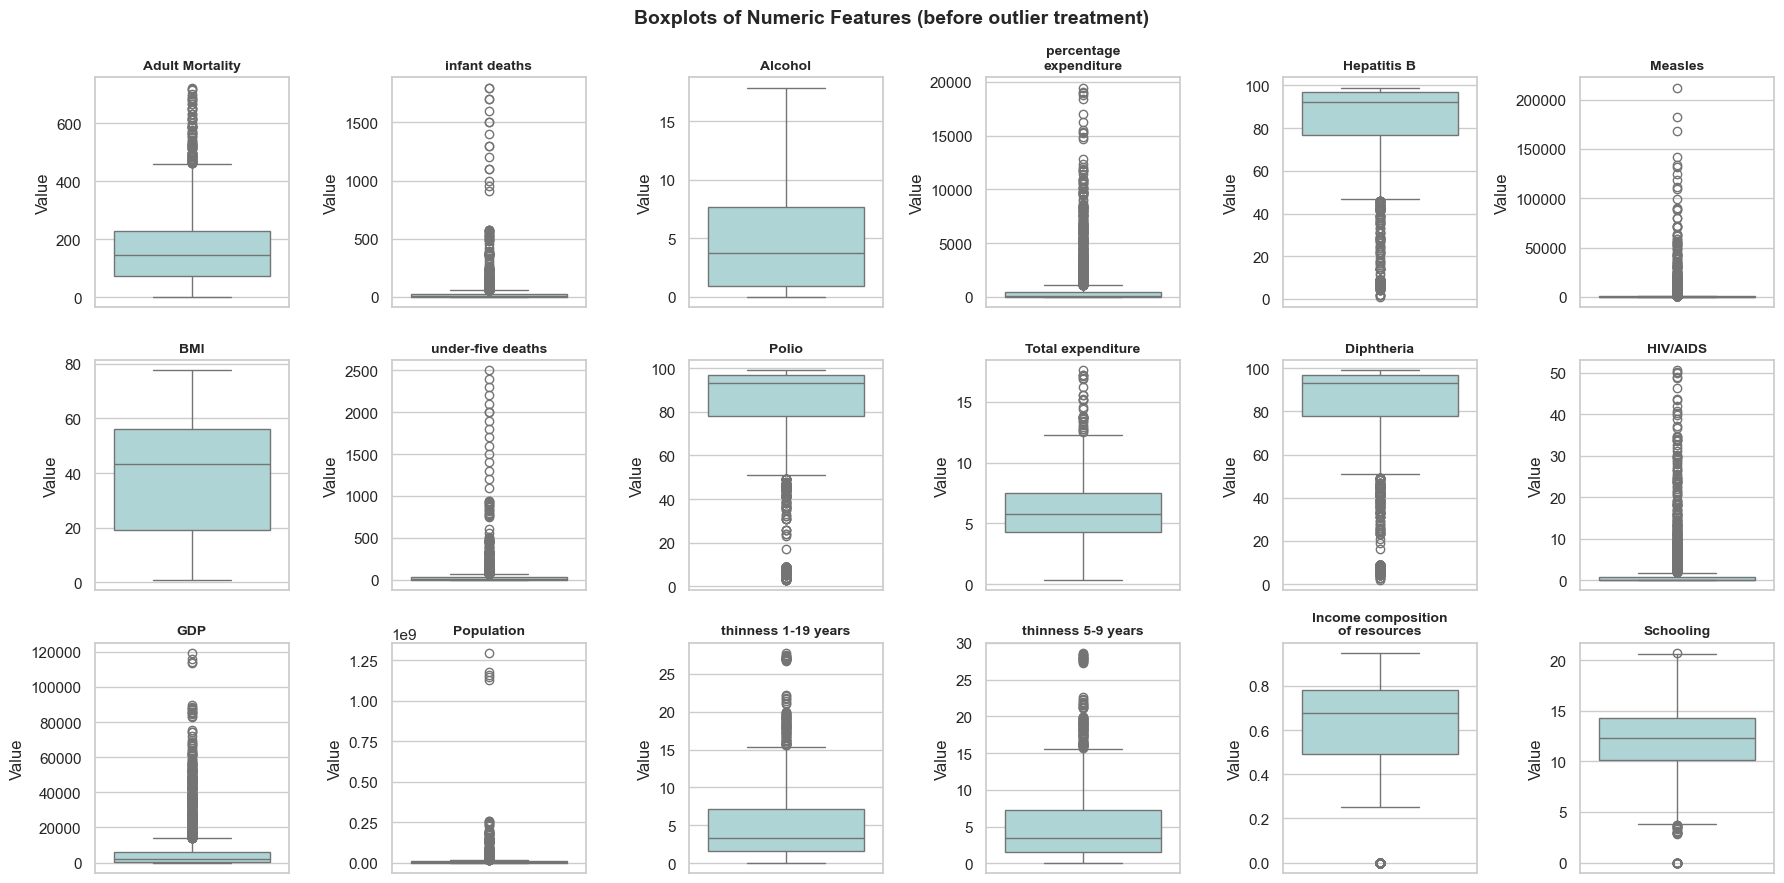

In [18]:
OUTLIER_COLS = [
    "Adult Mortality", "infant deaths", "Alcohol", "percentage expenditure",
    "Hepatitis B", "Measles", "BMI", "under-five deaths", "Polio",
    "Total expenditure", "Diphtheria", "HIV/AIDS", "GDP", "Population",
    "thinness 1-19 years", "thinness 5-9 years",
    "Income composition of resources", "Schooling",
]


def count_iqr_outliers(data, columns):
    """Count values outside the 1.5 x IQR fences for each column."""
    q1, q3 = data[columns].quantile(0.25), data[columns].quantile(0.75)
    iqr = q3 - q1
    outside = (data[columns] < q1 - 1.5 * iqr) | (data[columns] > q3 + 1.5 * iqr)
    summary = outside.sum().to_frame("Outliers")
    summary["Outliers (%)"] = (summary["Outliers"] / data[columns].notna().sum() * 100).round(1)
    return summary.sort_values("Outliers", ascending=False)


def plot_feature_grid(data, columns, kind, title, ncols=6):
    """Draw one small boxplot or histogram per feature in a grid."""
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    for ax, col in zip(axes.ravel(), columns):
        if kind == "box":
            sns.boxplot(y=data[col], color="#a8dadc", ax=ax)
            ax.set_xlabel("")
            ax.set_ylabel("Value")
        else:
            sns.histplot(data[col].dropna(), bins=30, color="#457b9d", ax=ax)
            ax.set_xlabel("Value")
            ax.set_ylabel("Count")
        ax.set_title(textwrap.fill(col, 20), fontsize=10)
    for ax in axes.ravel()[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


display(count_iqr_outliers(clean_df, OUTLIER_COLS))
plot_feature_grid(clean_df, OUTLIER_COLS, kind="box", title="Boxplots of Numeric Features (before outlier treatment)")

###  Feature consistency and plausibility checks
A few sanity checks on values that should obey simple rules.

In [19]:
immunisation_cols = ["Hepatitis B", "Polio", "Diphtheria"]

consistency_checks = pd.Series({
    "Immunisation coverage outside 0-100%": int(((clean_df[immunisation_cols] < 0) | (clean_df[immunisation_cols] > 100)).sum().sum()),
    "infant deaths greater than under-five deaths": int((clean_df["infant deaths"] > clean_df["under-five deaths"]).sum()),
    "BMI outside 10-60 (implausible as a country average)": int(((clean_df["BMI"] < 10) | (clean_df["BMI"] > 60)).sum()),
    "percentage expenditure above 100": int((clean_df["percentage expenditure"] > 100).sum()),
    "Population below 1,000": int((clean_df["Population"] < 1000).sum()),
}).to_frame("Rows flagged")
display(consistency_checks)

,Rows flagged
Immunisation coverage outside 0-100%,0
infant deaths greater than under-five deaths,0
BMI outside 10-60 (implausible as a country average),629
percentage expenditure above 100,1301
"Population below 1,000",30


Immunisation percentages are valid and infant deaths never exceed under-five deaths. However, several columns contain values that look inconsistent with their documented definitions (for example `BMI` values as low as 1 or as high as 77 for a country average, and `percentage expenditure` above 100). These values are **kept unchanged** to preserve the original analysis, because correcting them would require the original data source. They are noted in the Limitations section.

##  Exploratory Data Analysis
###  Dataset composition

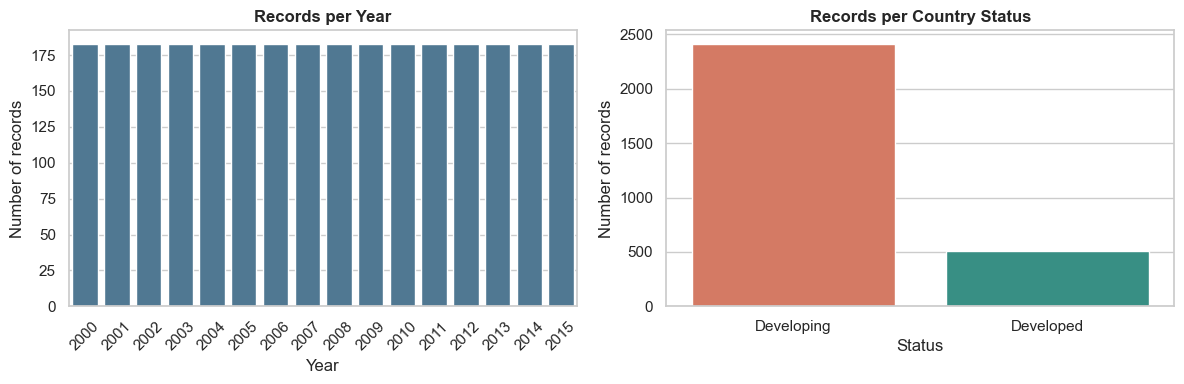

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=clean_df, x="Year", color="#457b9d", ax=axes[0])
axes[0].set(title="Records per Year", xlabel="Year", ylabel="Number of records")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(data=clean_df, x="Status", hue="Status", palette=STATUS_PALETTE, legend=False, ax=axes[1])
axes[1].set(title="Records per Country Status", xlabel="Status", ylabel="Number of records")

plt.tight_layout()
plt.show()

**Observation:** the data is perfectly balanced across years (183 countries in each of the 16 years). Developing countries make up the large majority of records (2,416 vs 512), so the two groups are imbalanced.

###  Distribution of life expectancy

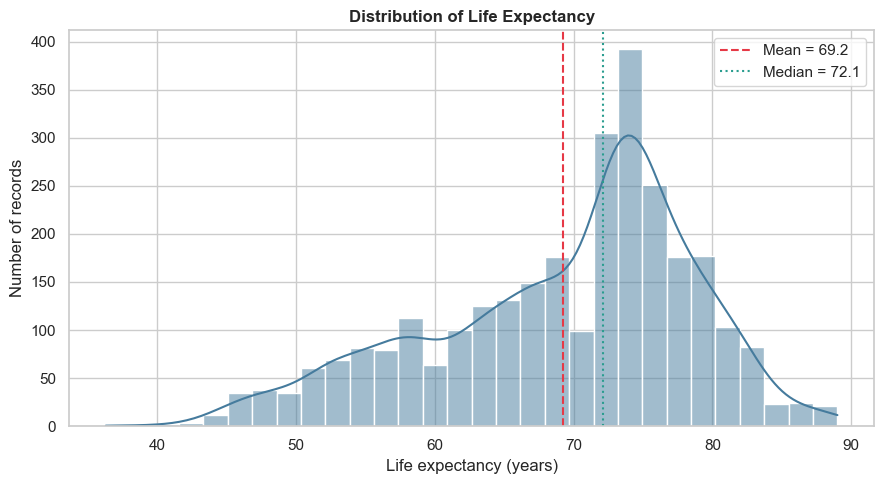

In [21]:
mean_le, median_le = clean_df[TARGET].mean(), clean_df[TARGET].median()

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(clean_df[TARGET], bins=30, kde=True, color="#457b9d", ax=ax)
ax.axvline(mean_le, color="#e63946", linestyle="--", label=f"Mean = {mean_le:.1f}")
ax.axvline(median_le, color="#2a9d8f", linestyle=":", label=f"Median = {median_le:.1f}")
ax.set(title="Distribution of Life Expectancy", xlabel="Life expectancy (years)", ylabel="Number of records")
ax.legend()
plt.tight_layout()
plt.show()

**Observation:** life expectancy is left-skewed. A long tail of low values (minimum 36.3 years) pulls the mean (69.2) below the median (72.1), while the bulk of records lie between roughly 63 and 76 years.

###  Developed vs developing countries: life expectancy

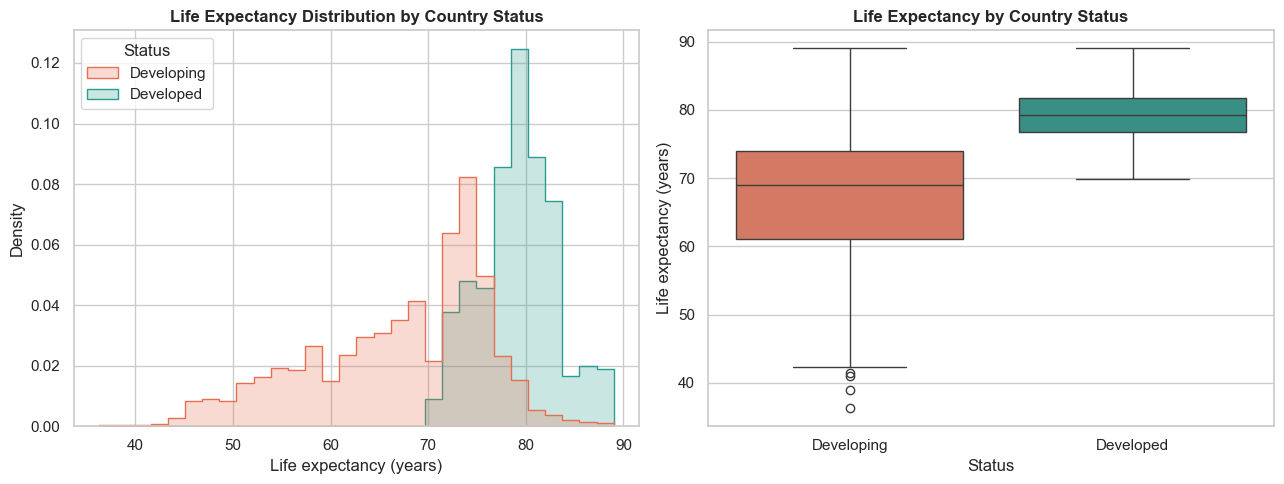

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=clean_df, x=TARGET, hue="Status", palette=STATUS_PALETTE, bins=30,
             stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(title="Life Expectancy Distribution by Country Status",
            xlabel="Life expectancy (years)", ylabel="Density")

sns.boxplot(data=clean_df, x="Status", y=TARGET, hue="Status", palette=STATUS_PALETTE,
            legend=False, ax=axes[1])
axes[1].set(title="Life Expectancy by Country Status", xlabel="Status", ylabel="Life expectancy (years)")

plt.tight_layout()
plt.show()

**Observation:** developed countries average 79.2 years versus 67.1 years for developing countries, and the developing group is far more spread out (standard deviation 9.0 vs 3.9 years). The distributions overlap only in the upper range of the developing group.

###  Life expectancy trend over time
The original notebook animated one line per country (193 frames). Plotting the yearly average for each group shows the same overall trend in a single readable chart.

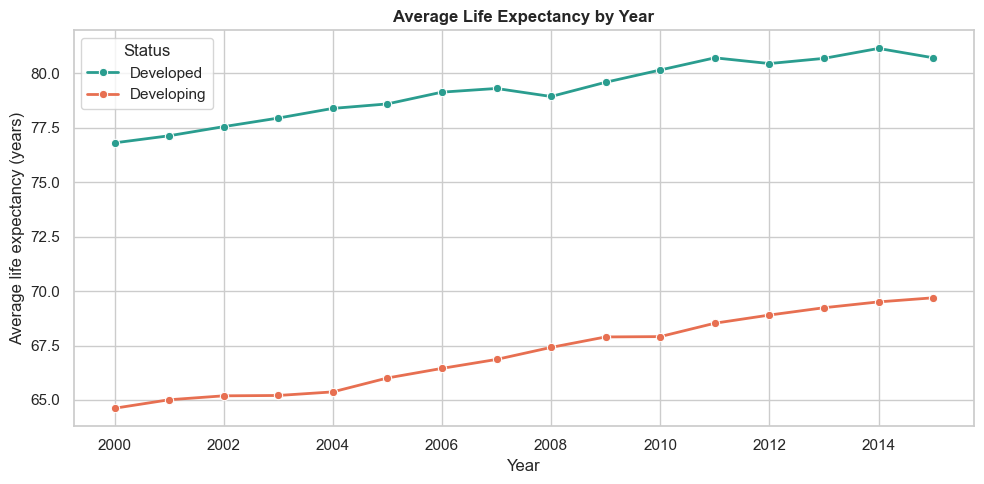

In [23]:
yearly_trend = clean_df.groupby(["Year", "Status"], as_index=False)[TARGET].mean()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=yearly_trend, x="Year", y=TARGET, hue="Status", palette=STATUS_PALETTE,
             marker="o", linewidth=2, ax=ax)
ax.set(title="Average Life Expectancy by Year", xlabel="Year", ylabel="Average life expectancy (years)")
plt.tight_layout()
plt.show()

**Observation:** average life expectancy rose in both groups between 2000 and 2015 (developed: 76.8 to 80.7 years; developing: 64.6 to 69.7 years). The developing group improved slightly more, but a gap of roughly 11 years remained in 2015.

### Distributions of the numeric features

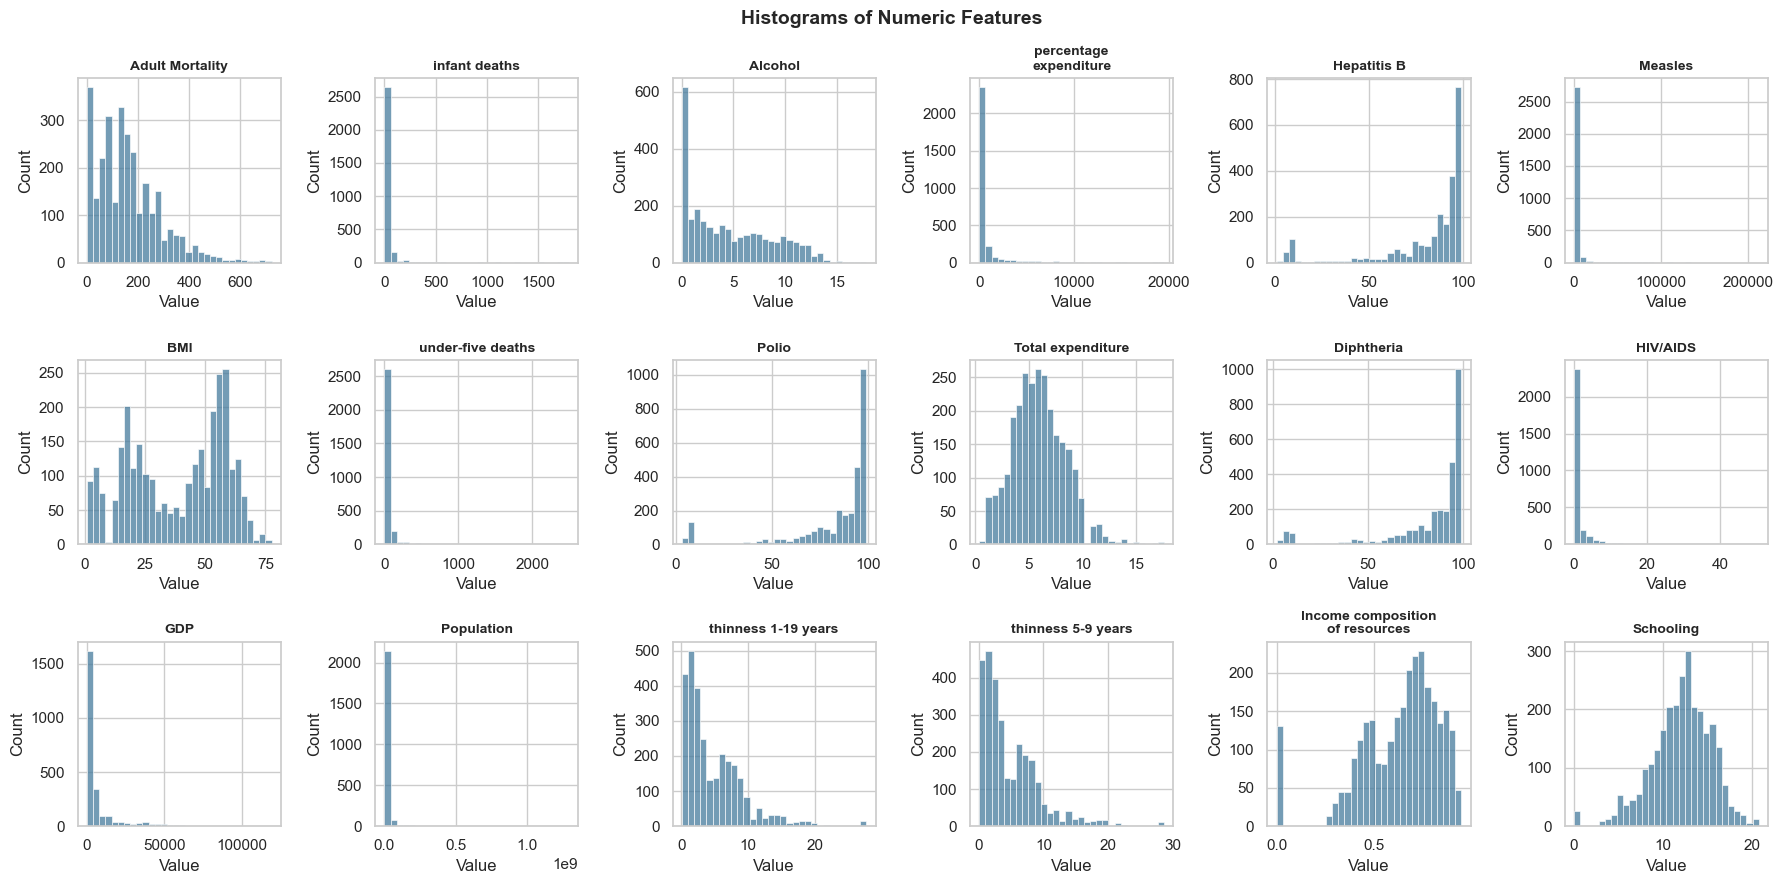

In [24]:
plot_feature_grid(clean_df, OUTLIER_COLS, kind="hist", title="Histograms of Numeric Features")

**Observation:** most indicators are strongly right-skewed (`infant deaths`, `under-five deaths`, `Measles`, `percentage expenditure`, `GDP`, `Population`, `HIV/AIDS`). Immunisation coverage (`Hepatitis B`, `Polio`, `Diphtheria`) piles up near 100%, `BMI` is bimodal, and `Income composition of resources` and `Schooling` contain a cluster of zero values (130 and 26 rows) that may be placeholders for unreported data.

### Relationship between key features and life expectancy
Each point is one country-year, coloured by country status. `r` is the Pearson correlation computed on the raw values. GDP is drawn on a logarithmic x-axis for readability only; the data itself is not transformed.

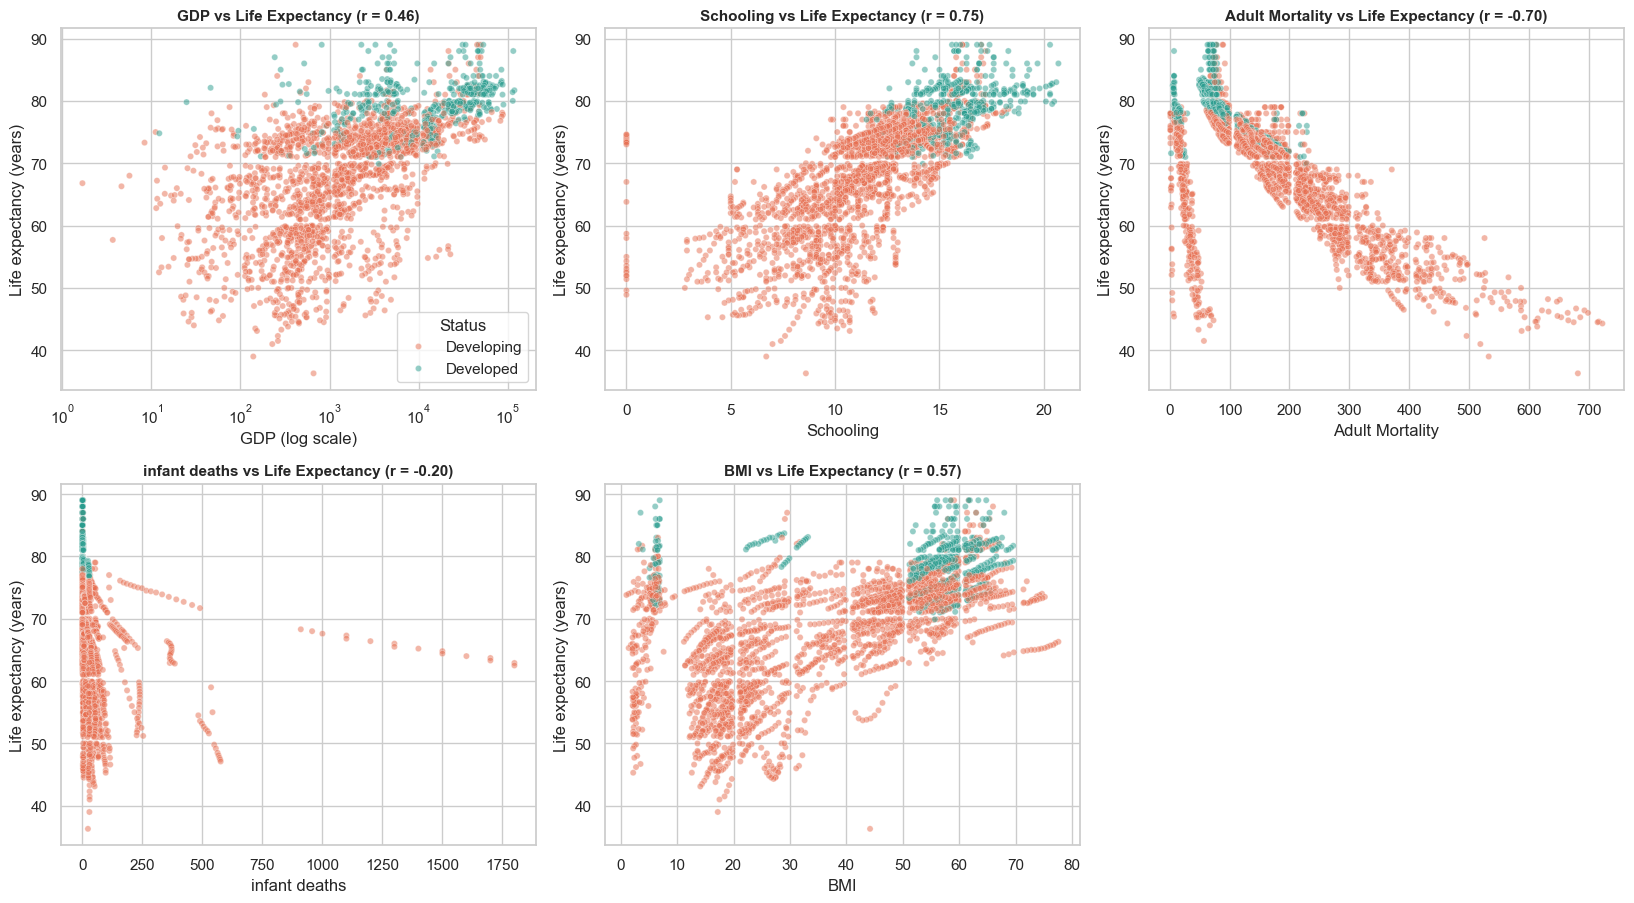

In [25]:
def plot_relationship_grid(data, features, log_x=(), ncols=3):
    """Scatter plots of the target against several features, coloured by status."""
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.6 * nrows))
    for i, (ax, feature) in enumerate(zip(axes.ravel(), features)):
        sns.scatterplot(data=data, x=feature, y=TARGET, hue="Status", palette=STATUS_PALETTE,
                        alpha=0.5, s=20, legend=(i == 0), ax=ax)
        r = data[[feature, TARGET]].corr().iloc[0, 1]
        ax.set_title(f"{feature} vs Life Expectancy (r = {r:.2f})", fontsize=11)
        ax.set_xlabel(f"{feature} (log scale)" if feature in log_x else feature)
        ax.set_ylabel("Life expectancy (years)")
        if feature in log_x:
            ax.set_xscale("log")
    for ax in axes.ravel()[len(features):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


plot_relationship_grid(
    clean_df,
    features=["GDP", "Schooling", "Adult Mortality", "infant deaths", "BMI"],
    log_x=("GDP",),
)

**Observation:** `Schooling` (r = 0.75) and `Adult Mortality` (r = -0.70) have the strongest linear relationships with life expectancy. `GDP` shows a clear but curved relationship: life expectancy rises steeply at low income and levels off at high income, which a straight line captures poorly. `infant deaths` has a weak linear correlation (r = -0.20), and developed countries cluster in the top-right of most panels.

###  Developed vs developing countries: key indicators

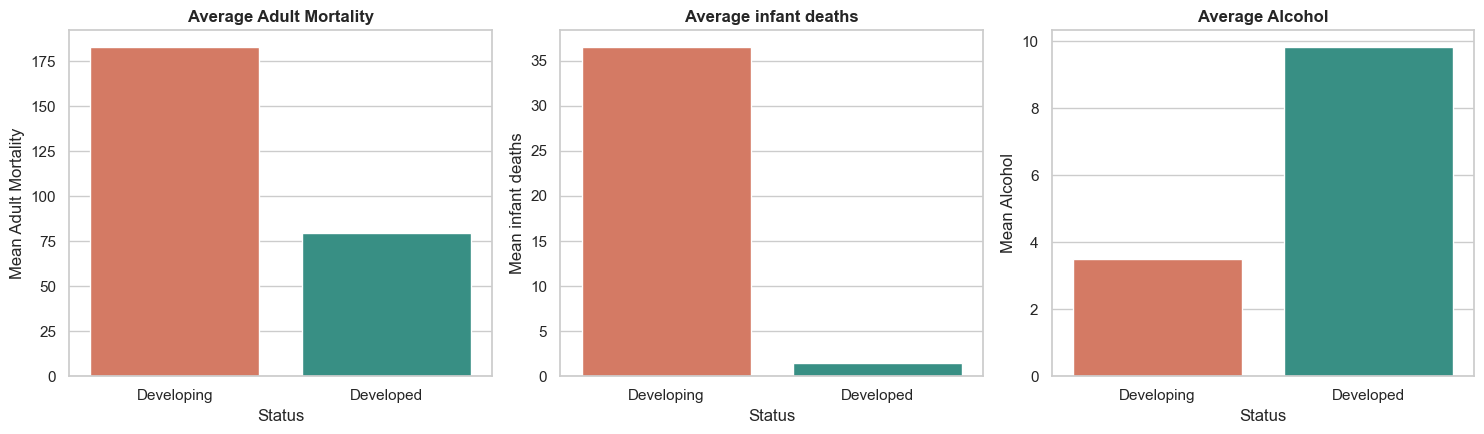

,Life expectancy,Adult Mortality,infant deaths,Alcohol,Schooling,GDP
Status,,,,,,
Developed,79.20,79.69,1.49,9.83,15.85,22053.39
Developing,67.11,182.83,36.53,3.49,11.23,4292.19


In [26]:
comparison_cols = ["Adult Mortality", "infant deaths", "Alcohol"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, comparison_cols):
    sns.barplot(data=clean_df, x="Status", y=col, hue="Status", palette=STATUS_PALETTE,
                errorbar=None, legend=False, ax=ax)
    ax.set(title=f"Average {col}", xlabel="Status", ylabel=f"Mean {col}")
plt.tight_layout()
plt.show()

display(clean_df.groupby("Status")[[TARGET, "Adult Mortality", "infant deaths", "Alcohol", "Schooling", "GDP"]].mean().round(2))

**Observation:** compared with developed countries, developing countries have more than twice the adult mortality (182.8 vs 79.7), a far higher infant death figure (36.5 vs 1.5), lower alcohol consumption (3.5 vs 9.8), fewer years of schooling (11.2 vs 15.9) and a much lower average GDP (about 4,300 vs 22,100). Since these indicators move together, the groups differ on many dimensions at once.

###  Correlation heatmap
Pairwise Pearson correlations between all numeric columns (missing values are ignored pairwise). The upper triangle is masked to avoid repetition.

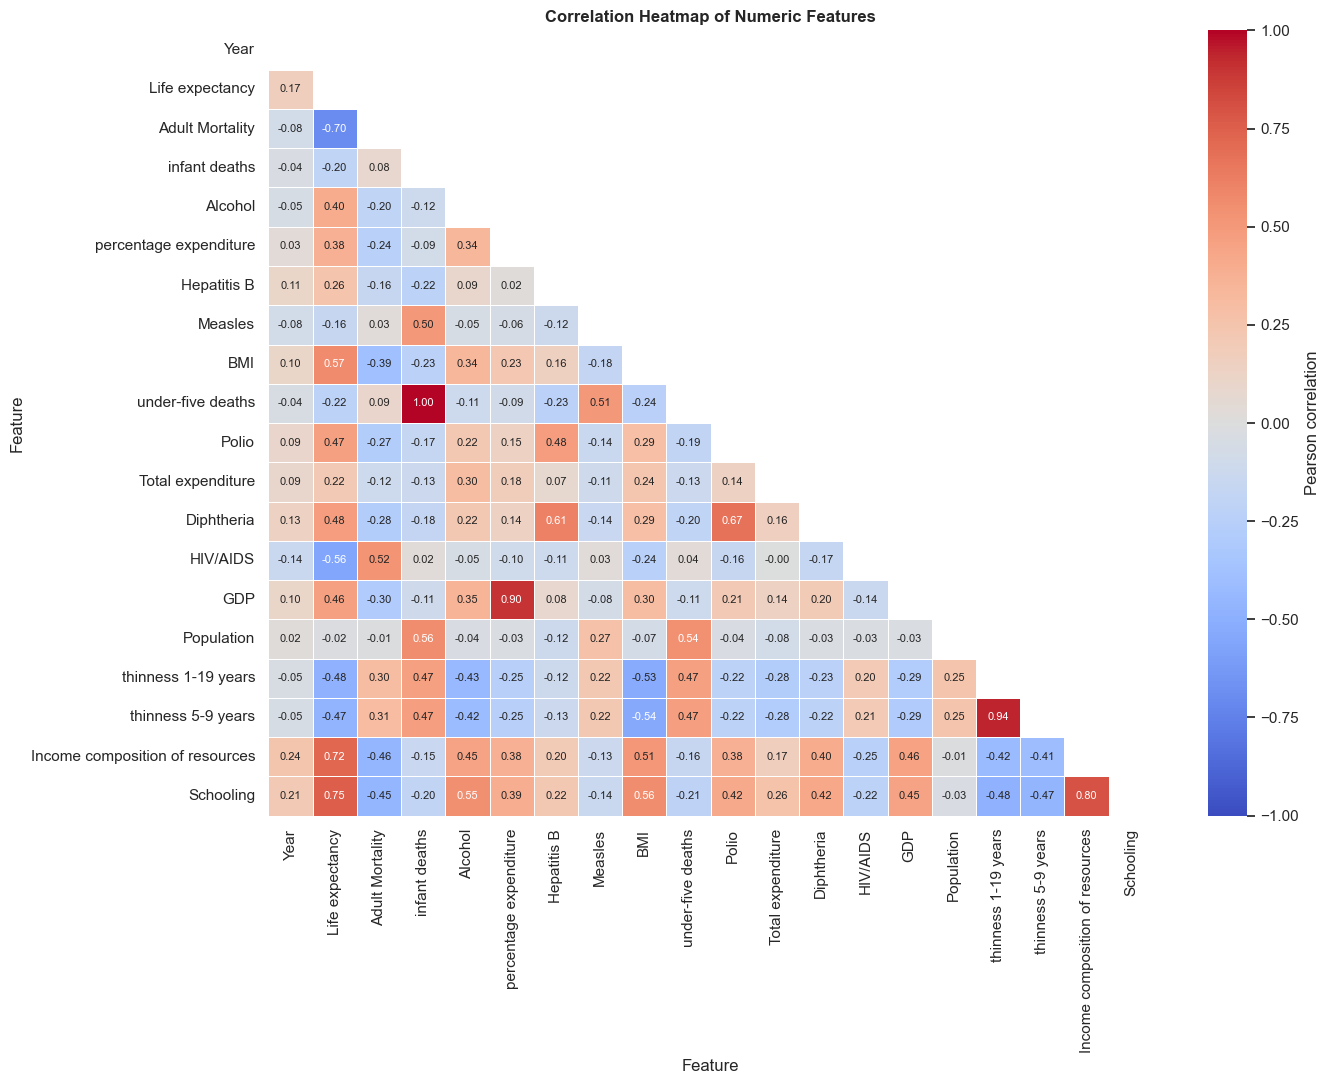

,Correlation with life expectancy
Schooling,0.752
Income composition of resources,0.725
BMI,0.568
Diphtheria,0.479
Polio,0.466
GDP,0.461
Alcohol,0.405
percentage expenditure,0.382
Hepatitis B,0.257
Total expenditure,0.218


In [27]:
corr_matrix = clean_df.select_dtypes(include="number").corr()
upper_mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr_matrix, mask=upper_mask, annot=True, fmt=".2f", annot_kws={"size": 8},
            cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Features")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
ax.grid(False)
plt.tight_layout()
plt.show()

display(corr_matrix[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_frame("Correlation with life expectancy"))

**Observation:**

- Strongest positive correlations with life expectancy: `Schooling` (0.75), `Income composition of resources` (0.73) and `BMI` (0.57).
- Strongest negative correlations: `Adult Mortality` (-0.70) and `HIV/AIDS` (-0.56).
- `Population` is essentially uncorrelated with life expectancy (-0.02).
- Several predictors are highly collinear: `infant deaths` and `under-five deaths` (about 1.00), the two `thinness` columns (0.94), `GDP` and `percentage expenditure` (0.90), and `Schooling` and `Income composition of resources` (0.80). This affects the interpretation of coefficients and feature importances.

> **Pairplot omitted:** with 20 numeric columns a pairplot is unreadable and the scatter plots above already show the most informative relationships.

##  Feature Engineering

In [28]:
model_df = clean_df.copy()

status_encoder = LabelEncoder()
country_encoder = LabelEncoder()
model_df["Status"] = status_encoder.fit_transform(model_df["Status"])
model_df["Country"] = country_encoder.fit_transform(model_df["Country"])

print("Status encoding:", dict(zip(status_encoder.classes_, status_encoder.transform(status_encoder.classes_))))
print(f"Country encoded as integers 0-{model_df['Country'].max()} ({model_df['Country'].nunique()} countries)")
model_df[["Country", "Status"]].head()

Status encoding: {'Developed': 0, 'Developing': 1}
Country encoded as integers 0-182 (183 countries)


,Country,Status
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


## Data Preprocessing



In [29]:
X = model_df.drop(columns=TARGET)
y = model_df[TARGET]

NUMERIC_FEATURES = [col for col in X.columns if col != "Status"]


class IQRMeanReplacer(BaseEstimator, TransformerMixin):
    """Replace values outside the 1.5 x IQR fences with the column mean.

    Fences and means are learned in ``fit`` (on the training set only) and then
    applied unchanged to any other data, so no test information leaks in.
    """

    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)
        q1 = X[self.columns].quantile(0.25)
        q3 = X[self.columns].quantile(0.75)
        iqr = q3 - q1
        self.lower_ = q1 - 1.5 * iqr
        self.upper_ = q3 + 1.5 * iqr
        self.means_ = X[self.columns].mean()
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.columns:
            is_outlier = (X[col] < self.lower_[col]) | (X[col] > self.upper_[col])
            X[col] = X[col].mask(is_outlier, self.means_[col])
        return X

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


preprocessing = Pipeline(steps=[
    ("impute_mean", ColumnTransformer(
        [("imputer", SimpleImputer(strategy="mean"), NUMERIC_FEATURES)],
        remainder="passthrough", verbose_feature_names_out=False)),
    ("replace_outliers", IQRMeanReplacer(columns=OUTLIER_COLS)),
    ("scale_minmax", ColumnTransformer(
        [("scaler", MinMaxScaler(), NUMERIC_FEATURES)],
        remainder="passthrough", verbose_feature_names_out=False)),
]).set_output(transform="pandas")

print(f"Features: {X.shape[1]} | Imputed and scaled: {len(NUMERIC_FEATURES)} | Outlier-treated: {len(OUTLIER_COLS)}")

Features: 21 | Imputed and scaled: 20 | Outlier-treated: 18


##  Train Test Split

The data is split 80 / 20 with `random_state=42`. The preprocessing pipeline is then fitted on the training set and only *applied* to the test set.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")

X_train_proc = preprocessing.fit_transform(X_train)
X_test_proc = preprocessing.transform(X_test)

assert not X_train_proc.isnull().any().any() and not X_test_proc.isnull().any().any()
print("\nPreprocessing fitted on the training set only; no missing values remain.")

X_train: (2342, 21) | y_train: (2342,)
X_test:  (586, 21) | y_test:  (586,)

Preprocessing fitted on the training set only; no missing values remain.


,Outliers before,Outliers after
HIV/AIDS,439,0
Measles,433,433
percentage expenditure,314,0
under-five deaths,311,0
infant deaths,259,0
Hepatitis B,255,0
Diphtheria,242,51
GDP,235,0
Polio,203,90
Population,160,0


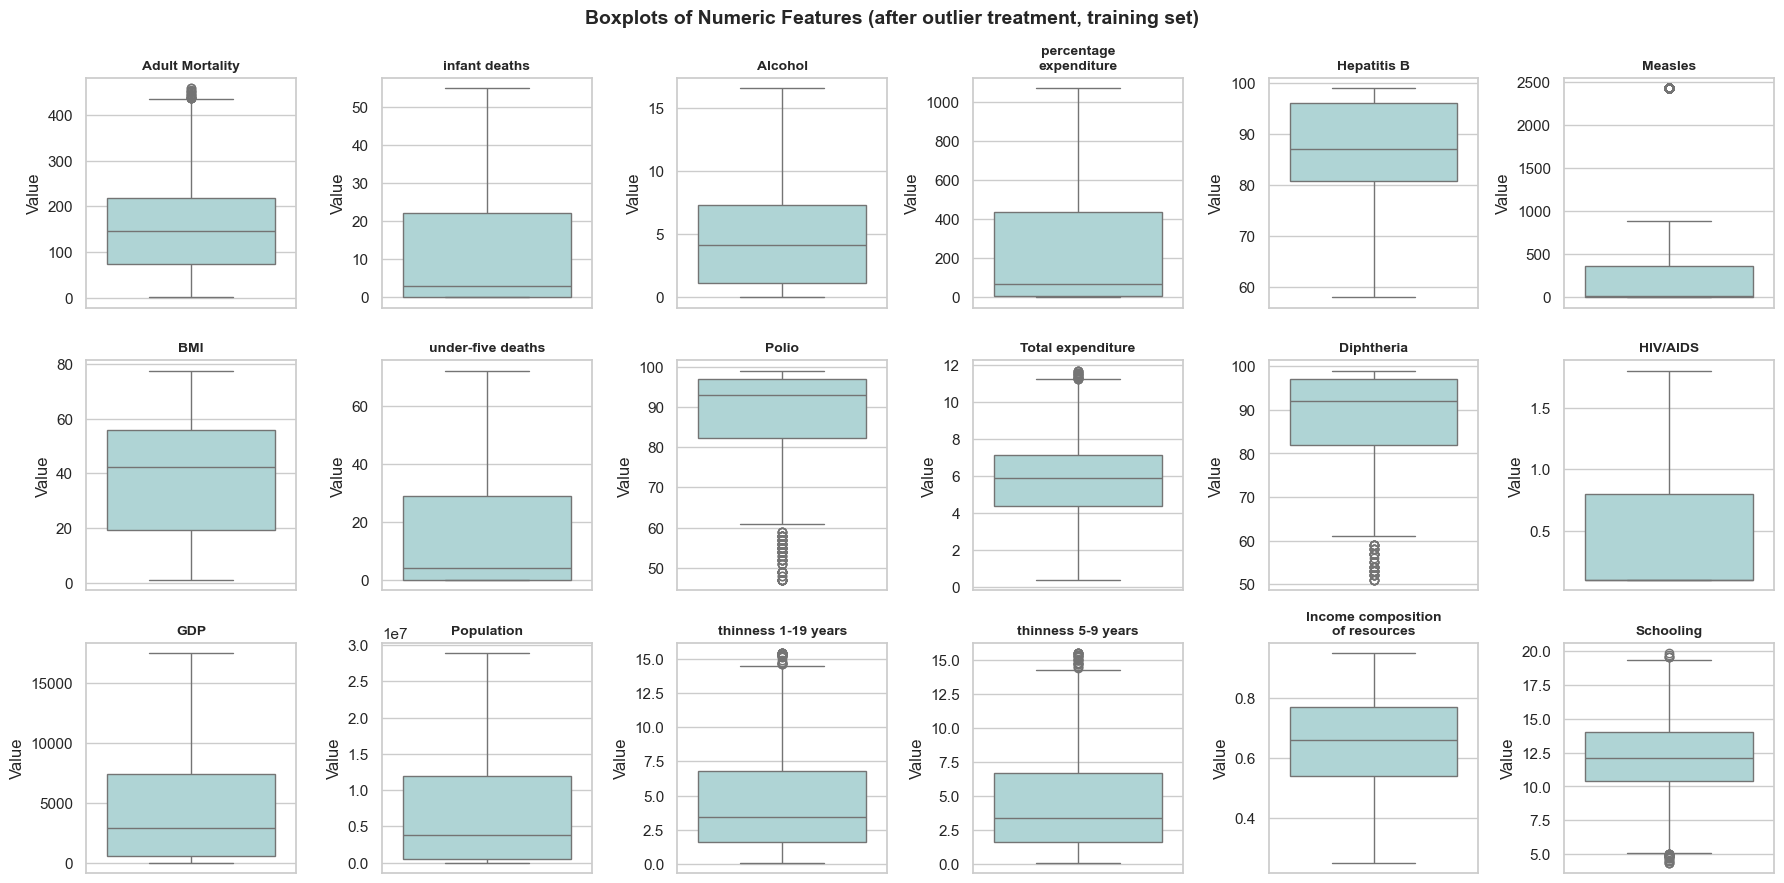

In [31]:
train_imputed = preprocessing[:1].transform(X_train)
train_treated = preprocessing[:2].transform(X_train)

outlier_effect = pd.DataFrame({
    "Outliers before": count_iqr_outliers(train_imputed, OUTLIER_COLS)["Outliers"],
    "Outliers after": count_iqr_outliers(train_treated, OUTLIER_COLS)["Outliers"],
}).sort_values("Outliers before", ascending=False)
display(outlier_effect)

plot_feature_grid(train_treated, OUTLIER_COLS, kind="box", title="Boxplots of Numeric Features (after outlier treatment, training set)")

##  Model Building

Three regression models are trained on the same preprocessed training data:

- **Linear Regression**: an interpretable linear baseline
- **Random Forest Regressor**: an ensemble of decision trees that can capture non-linear relationships
- **XGBoost Regressor**: gradient-boosted trees

Default hyperparameters are used for all models, with a fixed random seed for reproducibility.

In [32]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBRegressor(random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train_proc, y_train)
    print(f"Trained: {name}")

Trained: Linear Regression
Trained: Random Forest
Trained: XGBoost


Trained: XGBoost


##  Model Evaluation

Every model is scored on the unseen test set with **R²**, **MAE** and **RMSE** (both in years). Training R² is shown alongside to reveal over-fitting.

In [33]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te):
    """Return test R2, MAE, RMSE and train R2 for a fitted model."""
    predictions = model.predict(X_te)
    return {
        "R² (test)": r2_score(y_te, predictions),
        "MAE (years)": mean_absolute_error(y_te, predictions),
        "RMSE (years)": np.sqrt(mean_squared_error(y_te, predictions)),
        "R² (train)": r2_score(y_tr, model.predict(X_tr)),
    }


results = pd.DataFrame(
    {name: evaluate_model(model, X_train_proc, y_train, X_test_proc, y_test) for name, model in models.items()}
).T.sort_values("R² (test)", ascending=False)

display(results.round(3))

,R² (test),MAE (years),RMSE (years),R² (train)
XGBoost,0.967,1.101,1.678,0.999
Random Forest,0.965,1.076,1.743,0.994
Linear Regression,0.836,2.859,3.762,0.843


**Observation:**

- The two tree-based models are close: XGBoost has the highest test R² (0.966) and lowest RMSE, while Random Forest has the lowest MAE. With a single random split, the difference between them is small and should not be read as a decisive ranking.
- Both clearly outperform Linear Regression (R² 0.836, MAE about 2.9 years), which suggests the relationships between the indicators and life expectancy are non-linear.
- The tree models fit the training data almost perfectly (train R² 0.994 and 0.999) and score about 0.03 lower on the test set, a mild degree of over-fitting. Linear Regression's train and test scores are nearly identical, so it is limited by its form rather than over-fitted.


###  Actual vs predicted

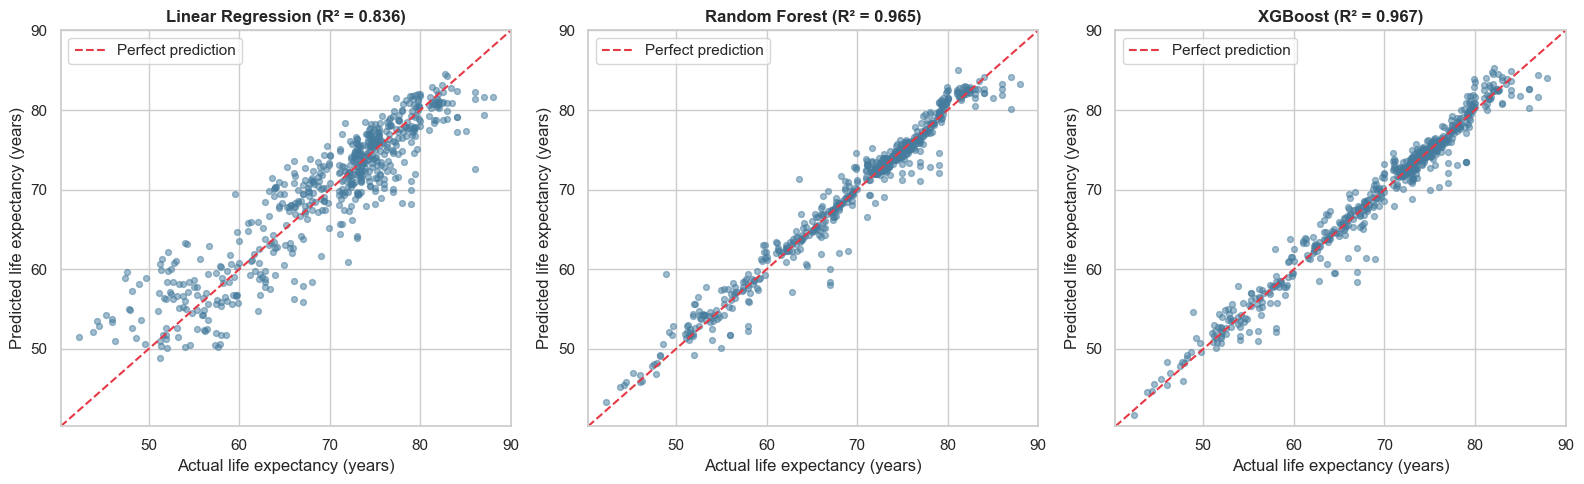

In [34]:
predictions = {name: model.predict(X_test_proc) for name, model in models.items()}
axis_limits = (y_test.min() - 2, y_test.max() + 2)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.5, s=18, color="#457b9d")
    ax.plot(axis_limits, axis_limits, color="#e63946", linestyle="--", label="Perfect prediction")
    ax.set(title=f"{name} (R² = {r2_score(y_test, y_pred):.3f})",
           xlabel="Actual life expectancy (years)", ylabel="Predicted life expectancy (years)",
           xlim=axis_limits, ylim=axis_limits)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

###  Residual analysis

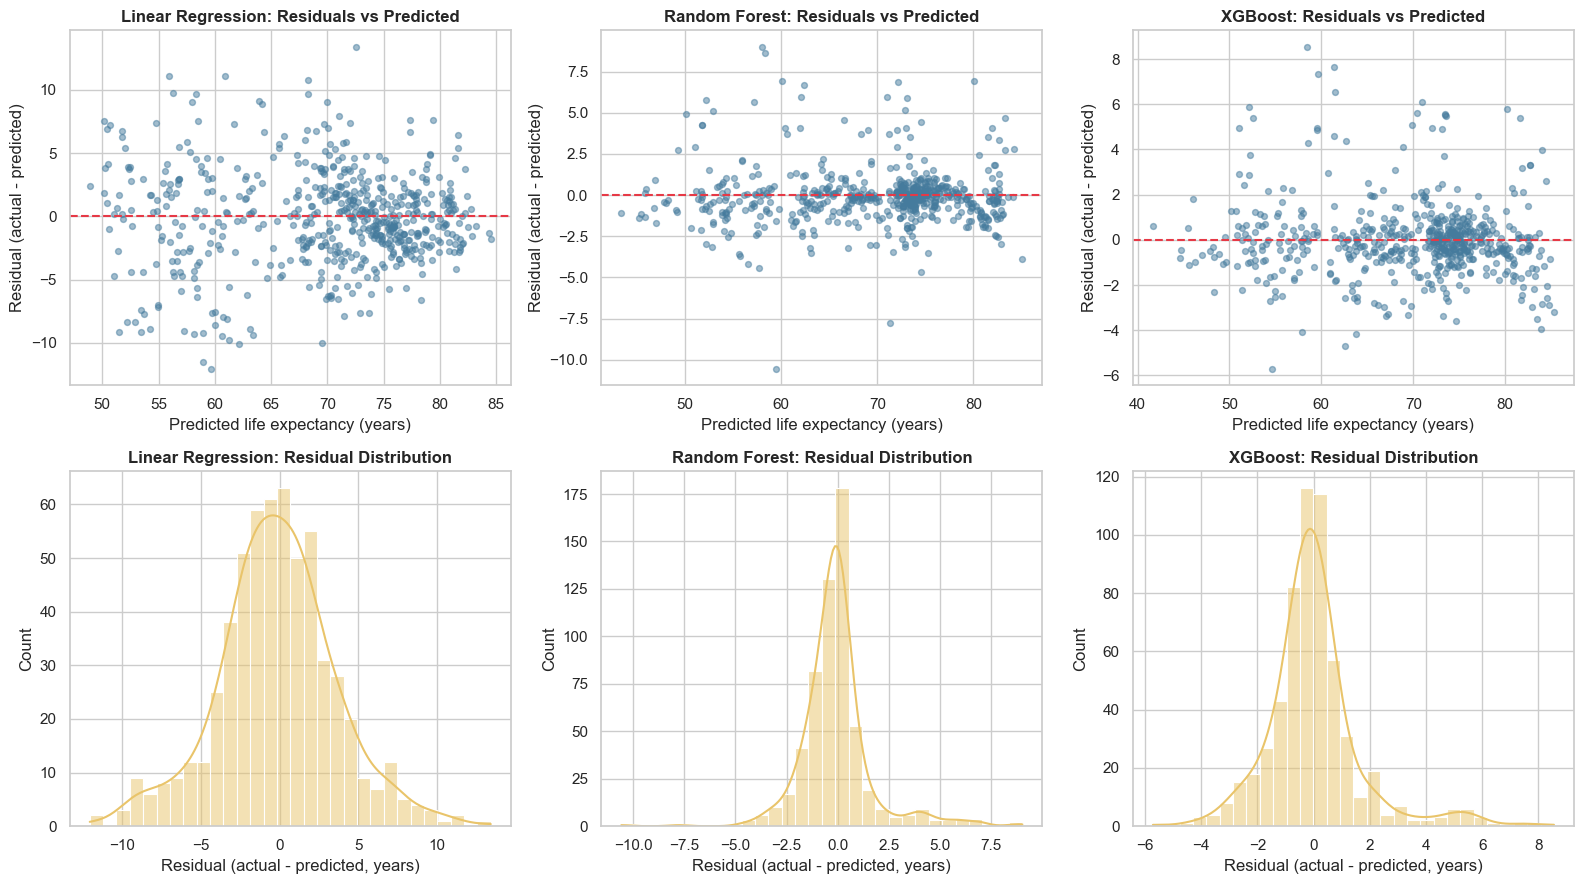

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, (name, y_pred) in enumerate(predictions.items()):
    residuals = y_test - y_pred

    axes[0, col].scatter(y_pred, residuals, alpha=0.5, s=18, color="#457b9d")
    axes[0, col].axhline(0, color="#e63946", linestyle="--")
    axes[0, col].set(title=f"{name}: Residuals vs Predicted",
                     xlabel="Predicted life expectancy (years)", ylabel="Residual (actual - predicted)")

    sns.histplot(residuals, bins=30, kde=True, color="#e9c46a", ax=axes[1, col])
    axes[1, col].set(title=f"{name}: Residual Distribution",
                     xlabel="Residual (actual - predicted, years)", ylabel="Count")
plt.tight_layout()
plt.show()

**Observation:** Linear Regression residuals are roughly symmetric around zero but wide (up to about ±10 years) and show a systematic pattern against the predicted value, again pointing to non-linearity. Random Forest and XGBoost residuals are tightly centred on zero, with most predictions within a few years of the truth and a small number of larger errors (up to roughly 8 to 10 years).

##  Feature Importance

Impurity-based importances from the two tree-based models (they sum to 1 per model). Linear Regression has no equivalent measure, so it is not shown.

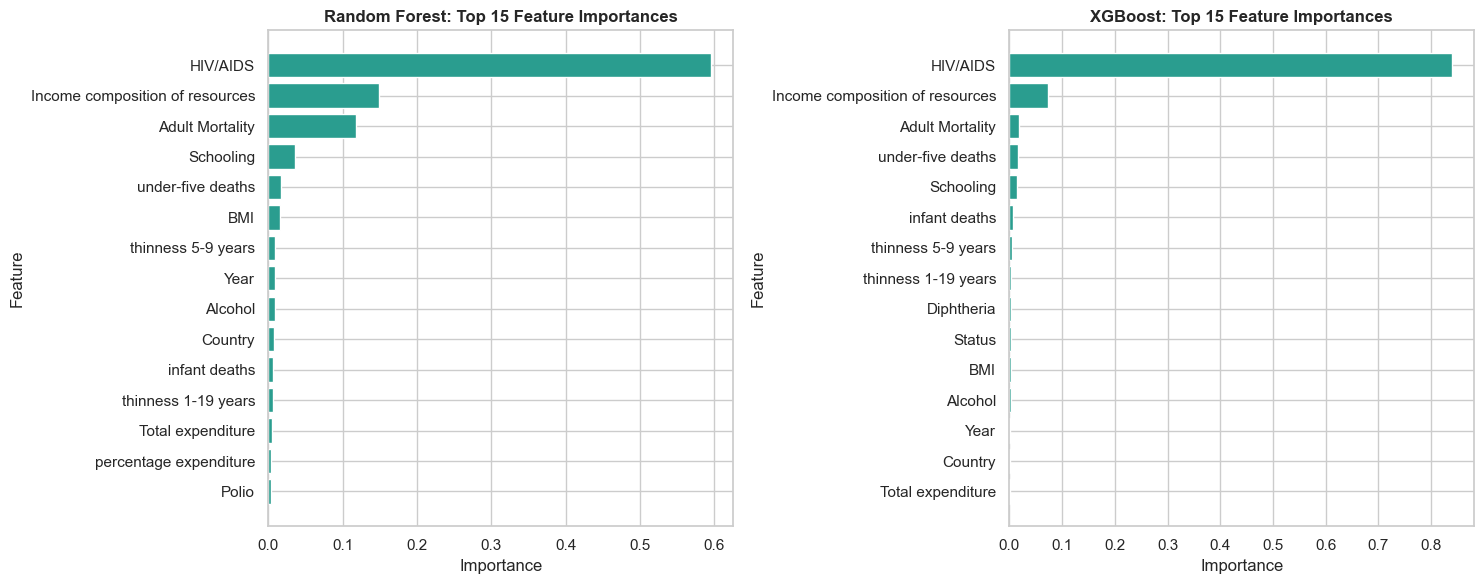

,Random Forest,XGBoost
HIV/AIDS,0.596,0.839
Income composition of resources,0.149,0.074
Adult Mortality,0.118,0.018
Schooling,0.036,0.015
under-five deaths,0.017,0.016
BMI,0.015,0.003
thinness 5-9 years,0.009,0.006
Year,0.009,0.002
Alcohol,0.008,0.003
Country,0.007,0.002


In [36]:
importance_df = pd.DataFrame(
    {
        "Random Forest": models["Random Forest"].feature_importances_,
        "XGBoost": models["XGBoost"].feature_importances_,
    },
    index=X_train_proc.columns,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, model_name in zip(axes, importance_df.columns):
    top_features = importance_df[model_name].sort_values().tail(15)
    ax.barh(top_features.index, top_features.values, color="#2a9d8f")
    ax.set(title=f"{model_name}: Top 15 Feature Importances", xlabel="Importance", ylabel="Feature")
plt.tight_layout()
plt.show()

display(importance_df.sort_values("Random Forest", ascending=False).head(10).round(3))

**Observation:** both models rank `HIV/AIDS` first, and by a wide margin in XGBoost (0.86). Random Forest also relies on `Income composition of resources`, `Adult Mortality` and `Schooling`. This ranking differs from the correlation ranking in Section 7.8, where `Schooling` and `Income composition of resources` were strongest, because tree models can use `HIV/AIDS` to separate a subset of countries with very low life expectancy even though its overall linear correlation is weaker. Impurity-based importances are also split between correlated features, so closely related columns (for example `Schooling` and `Income composition of resources`) understate each other.